In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
# 1.- Trabajar con el dataset
data = pd.read_csv('titanic.csv')

In [3]:
# 2.- Preprocesar los datos
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
data = data[features + ['Survived']].dropna()

In [4]:
# Codificar variables categóricas
label_encoders = {}
for column in ['Sex', 'Embarked']:
    le = LabelEncoder()
    data[column] = le.fit_transform(data[column])
    label_encoders[column] = le

In [5]:
# Separar características (X) y etiquetas (y)
X = data.drop('Survived', axis=1).values
y = data['Survived'].values

In [6]:
# Escalar las variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
# Dividir el conjunto de datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [8]:
# 3.- Definir el modelo de la red neuronal
model = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(7,)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
# 4.- Compilar el modelo
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [10]:
# 5.- Entrenar el modelo
history = model.fit(
    X_train, y_train,
    epochs=800,
    batch_size=32,
    validation_split=0.2,
    verbose=0 # Cambiado a 0 para no saturar la consola, puedes volver a ponerlo en 1 si prefieres ver el progreso
)

In [11]:
# 6.- Evaluación del modelo y métricas avanzadas
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

In [12]:
# Obtener predicciones de probabilidad y convertirlas a clases binarias (0 o 1)
y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype("int32").flatten()

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [13]:
# Calcular métricas con Scikit-Learn
acc = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

In [14]:
print(f"--- MÉTRICAS EN EL CONJUNTO DE PRUEBA ---")
print(f"Pérdida (Loss): {test_loss:.4f}")
print(f"Accuracy (Precisión global): {acc:.4f}")
print(f"Recall (Sensibilidad): {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("\nMatriz de Confusión:")
print(cm)

--- MÉTRICAS EN EL CONJUNTO DE PRUEBA ---
Pérdida (Loss): 0.7180
Accuracy (Precisión global): 0.7762
Recall (Sensibilidad): 0.6349
F1-Score: 0.7143

Matriz de Confusión:
[[71  9]
 [23 40]]


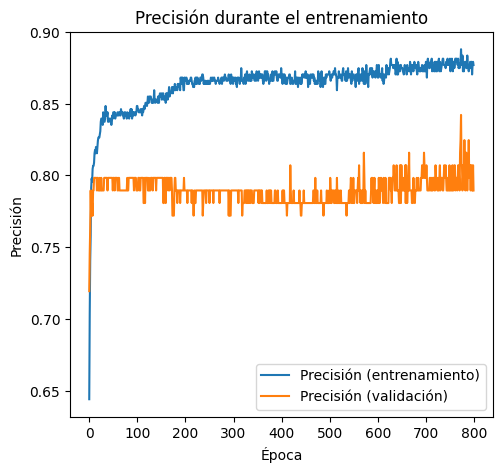

In [15]:
# Gráfica 1: Historial de precisión durante el entrenamiento
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Precisión (entrenamiento)')
plt.plot(history.history['val_accuracy'], label='Precisión (validación)')
plt.title('Precisión durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

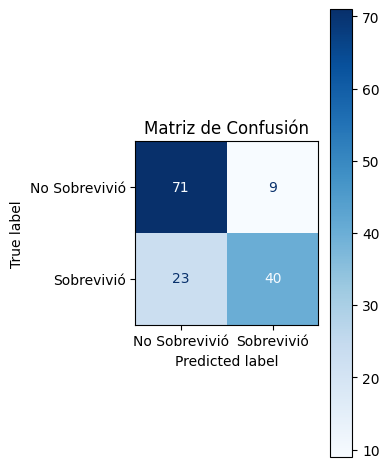

In [16]:
# Gráfica 2: Matriz de confusión visual
plt.subplot(1, 2, 2)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sobrevivió', 'Sobrevivió'])
disp.plot(cmap=plt.cm.Blues, ax=plt.gca(), values_format='d')
plt.title('Matriz de Confusión')

plt.tight_layout()
plt.show()